In [235]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib
import numpy as np
import scipy.optimize
import odrpack

plt.rcParams["figure.dpi"] = 150
plt.rcParams["text.usetex"] = True
plt.rcParams["font.size"] = 12


# matplotlib.rcParams['mathtext.fontset'] = 'stix'
# matplotlib.rcParams['font.family'] = 'Computer Modern'


plt.rcParams['font.family'] = 'serif' # or 'sans-serif' or 'monospace'
plt.rcParams['font.serif'] = 'cmr10'
plt.rcParams['font.sans-serif'] = 'cmss10'
plt.rcParams['font.monospace'] = 'cmtt10'
plt.rcParams["axes.formatter.use_mathtext"] = True # to fix the minus signs
%config InlineBackend.figure_format = 'retina'
#plt.rcParams['axes.grid'] = True

In [236]:
def string_to_float_list(data_string: str):
    return np.array([float(x) for x in data_string.split()])

In [237]:
c = 299792458 # m / s


In [238]:
intensities_0 = string_to_float_list("""2
408
7232
14000
18600
31285
44410
61000
""")

currents_0 = string_to_float_list("""0
10
123
211
284
411
521
655
""")

intensities_100 = string_to_float_list("""2
408
7232
14000
18600
31285
44410
61000
""")

currents_100 = string_to_float_list("""3
18
265
433
582
754
1034
1249
""")


intensities_400 = string_to_float_list("""2
408
7232
14000
18600
31285
44410
61000
""")

currents_400 = string_to_float_list("""0
65
936
1358
1745
2366
2880
3411
""")


currents_0_err = np.full(len(currents_0), 8)
intensities_0_err = np.full(len(intensities_0), 1)

currents_100_err = np.full(len(currents_100), 8)
intensities_100_err = np.full(len(intensities_100), 1)

currents_400_err = np.full(len(currents_400), 8)
intensities_400_err = np.full(len(intensities_400), 1)


In [239]:
def linear_fit(x, m):
    return m*x



popt_0, pcov_0 = scipy.optimize.curve_fit(linear_fit, intensities_0, currents_0)
popt_100, pcov_100 = scipy.optimize.curve_fit(linear_fit, intensities_100, currents_100)
popt_400, pcov_400 = scipy.optimize.curve_fit(linear_fit, intensities_400, currents_400)

m_0 = popt_0[0]
m_0_err = np.sqrt(pcov_0[0][0])

m_100 = popt_100[0]
m_100_err = np.sqrt(pcov_100[0][0])

m_400 = popt_400[0]
m_400_err = np.sqrt(pcov_400[0][0])

61141.460165190125


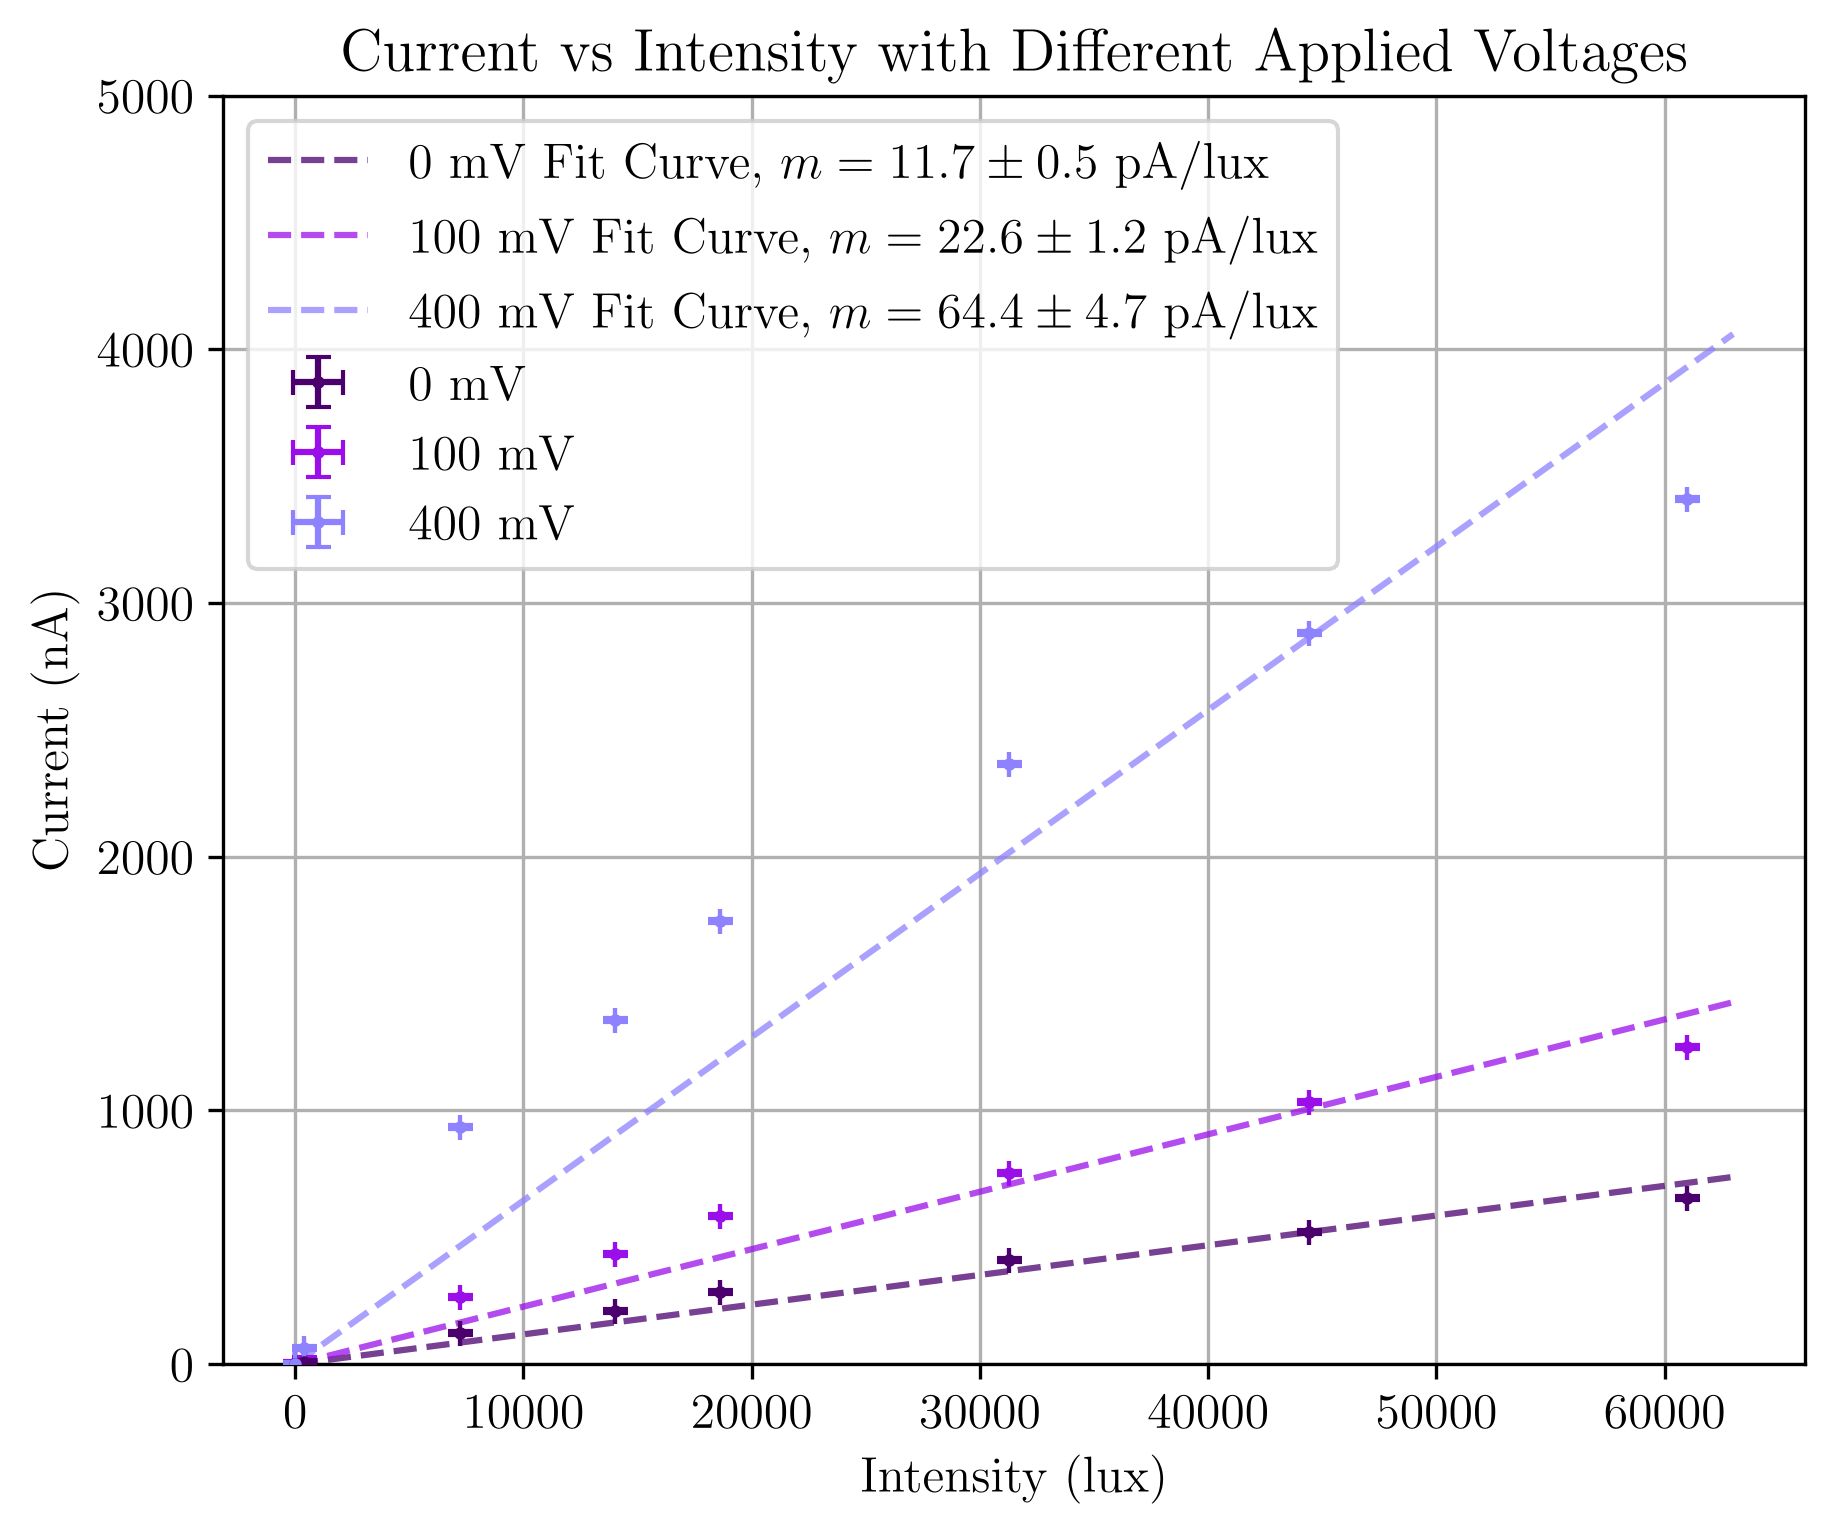

In [240]:
fig, axs = plt.subplots(1, figsize=(6, 5), layout="constrained")

axs.grid()


#IV_axs[1].plot(np.linspace(green_voltages.min(), green_voltages.max(), 200), IV_func(np.linspace(green_voltages.min(), green_voltages.max(), 200), *popt_IV_G))
axs.errorbar(intensities_0, currents_0, currents_0_err, intensities_0_err, fmt = 'o', markersize = 2, capsize = 3, color = 'xkcd:royal purple', zorder=10, label = "0 mV")
axs.errorbar(intensities_100, currents_100, currents_100_err, intensities_100_err, fmt = 'o', markersize = 2, capsize = 3, color = 'xkcd:violet', zorder=5, label = "100 mV")
axs.errorbar(intensities_400, currents_400, currents_400_err, intensities_400_err, fmt = 'o', markersize = 2, capsize = 3, color = 'xkcd:periwinkle', zorder=10, label = "400 mV")


axs.set_ylim(0, 5000)
xvals = np.linspace(0, 63000, 500)

axs.plot(xvals, linear_fit(xvals, m_0), color = 'xkcd:royal purple', alpha = 0.75, linestyle="dashed", label = rf"0 mV Fit Curve, $m = {m_0*1e3:0.1f} \pm {m_0_err*1e3:0.1f}$ pA/lux")
axs.plot(xvals, linear_fit(xvals, m_100), color = 'xkcd:violet', alpha = 0.75, linestyle="dashed", label = rf"100 mV Fit Curve, $m = {m_100*1e3:0.1f} \pm {m_100_err*1e3:0.1f}$ pA/lux")
axs.plot(xvals, linear_fit(xvals, m_400), color = 'xkcd:periwinkle', alpha = 0.75, linestyle="dashed", label = rf"400 mV Fit Curve, $m = {m_400*1e3:0.1f} \pm {m_400_err*1e3:0.1f}$ pA/lux")

axs.legend()


axs.set_xlabel("Intensity (lux)")
axs.set_ylabel("Current (nA)")


axs.set_title("Current vs Intensity with Different Applied Voltages")


fig.savefig("plots/current_intensity_curve.png", dpi=300)


chi2_0 = np.sum((currents_0 - linear_fit(currents_0, m_0))**2 / (currents_0_err**2 + (m_0*intensities_0_err)**2)) / (len(currents_0) - 1)
chi2_100 = np.sum((currents_100 - linear_fit(currents_100, m_100))**2 / (currents_100_err**2 + (m_100*intensities_100_err)**2)) / (len(currents_100) - 1)
chi2_400 = np.sum((currents_400 - linear_fit(currents_400, m_400))**2 / (currents_400_err**2 + (m_400*intensities_400_err)**2)) / (len(currents_400) - 1)

print(chi2_400)